In [1]:
from demandpilot.data.ingest import load_retail_data

data = load_retail_data()
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


In [2]:
data.shape, data.dtypes

((1067371, 9),
 Invoice                object
 StockCode              object
 Description            object
 Quantity                int64
 InvoiceDate    datetime64[us]
 Price                 float64
 Customer ID           float64
 Country                   str
 SourceSheet               str
 dtype: object)

In [3]:
(
    data.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_rate=lambda x: x["missing_count"] / len(data))
    .sort_values("missing_rate", ascending=False)
)

,missing_count,missing_rate
Customer ID,243007,0.227669
Description,4382,0.004105
Invoice,0,0.000000
Quantity,0,0.000000
StockCode,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
Country,0,0.000000
SourceSheet,0,0.000000


<Axes: title={'center': 'Daily Retail Transaction Volume'}, xlabel='InvoiceDate'>

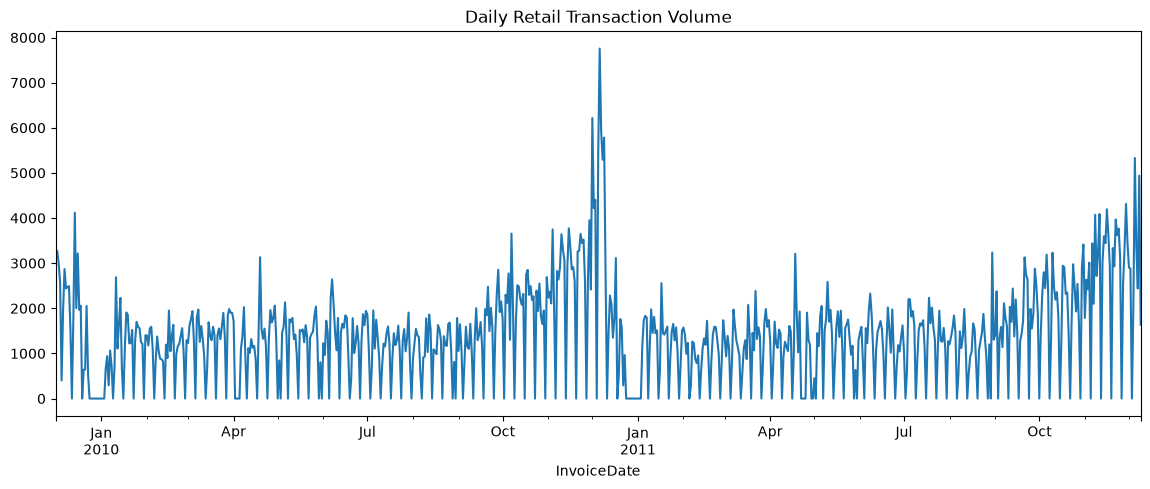

In [4]:
data["InvoiceDate"] = data["InvoiceDate"].astype("datetime64[ns]")

daily_transactions = (
    data.set_index("InvoiceDate")
    .resample("D")
    .size()
)

daily_transactions.plot(
    figsize=(14, 5),
    title="Daily Retail Transaction Volume",
)

<Axes: title={'center': 'Top 10 Countries by Transaction Rows'}, xlabel='Country'>

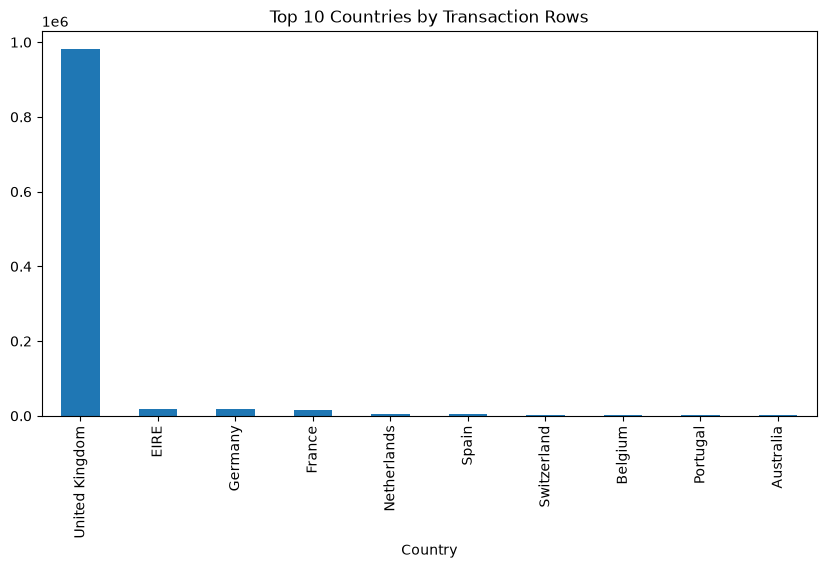

In [5]:
data["Country"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Countries by Transaction Rows",
)